# Proyecto final: integración de datos y prospectiva en FitBalance Gym

**Juan José Zapata y Juanita Pineda**

## Pregunta de negocio
¿Cómo cambia la caracterización de las pérdidas por cancelaciones al incorporar un escenario externo comparable, y qué presupuesto podría destinarse a financiar captura de GEI bajo diferentes niveles de gestión?

**Alcance:** empresas ficticias y escenario académico. La base interna del gimnasio se conserva intacta. GymPulse es una simulación calibrada a partir de ella; reproduce sus pares frecuencia–severidad con un incremento supuesto del 3 % en severidad y un orden elegido durante la calibración. Se probaron órdenes para obtener el 95 % en el primer método y disminuir las discrepancias de una muestra. No es evidencia independiente ni una prueba predictiva fuera de muestra. `Trazabilidad_simulacion.csv` identifica la fila interna usada en cada fila externa.

Se aplican dos modelos de integración vistos en clase: (1) pertenencia sobre pérdida agregada y (2) integración multidimensional por cercanía a centros. Credibilidad y lógica difusa complementan la comparación. La prospectiva usa una tercera base de supuestos editables.

## 1. Carga desde Drive

En Drive, la carpeta verificada es `Integracion de datos`. Guarda las tres bases dentro de `Proyecto_Final_FitBalance_GymPulse`. En el repositorio, las mismas bases están en `data/`. Ejecuta las celdas en orden.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
import os
from google.colab import drive

drive.mount('/content/drive')
ruta = "/content/drive/MyDrive/Integracion de datos/Proyecto_Final_FitBalance_GymPulse/"
os.makedirs("resultados", exist_ok=True)


In [1]:
df = pd.read_excel(ruta + "FitBalance_interna.xlsx", sheet_name="Datos")
GymPulse = pd.read_excel(ruta + "GymPulse_simulada.xlsx", sheet_name=0)
escenarios = pd.read_csv(ruta + "Escenarios_GEI.csv")

Freq = df["Frecuencia"].to_numpy(dtype=float)
Sev = df["Severidad"].to_numpy(dtype=float)
LDA = Freq * Sev
Freqe = GymPulse["Frecuencia_Cancelaciones_Dia"].to_numpy(dtype=float)
Seve = GymPulse["Severidad_COP_Cliente"].to_numpy(dtype=float)
LDAe = Freqe * Seve

print("Interna:", df.shape, "Externa simulada:", GymPulse.shape)
print("Rango interno:", df["Fecha"].min(), "a", df["Fecha"].max())
print("Media interna:", round(LDA.mean(), 2), "COP/día")
print("Media externa:", round(LDAe.mean(), 2), "COP/día")
print(escenarios.to_string(index=False))


Interna: (1200, 8) Externa simulada: (1200, 7)
Rango interno: 2023-01-01 00:00:00 a 2026-04-14 00:00:00
Media interna: 1324055.99 COP/día
Media externa: 1363777.67 COP/día
 NG  Horizonte_dias  Costo_contacto_COP  Fraccion_para_GEI  Costo_tCO2e_COP
1.0             365               30000                0.1           300000
1.1             365               30000                0.1           300000
1.2             365               30000                0.1           300000
1.5             365               30000                0.1           300000
2.0             365               30000                0.1           300000


## 2. Bases, variables e integración potencial

| Variable interna | Variable externa | Tipo y unidad | Uso |
|---|---|---|---|
| Día | Dia | Identificador del registro | Trazabilidad con prefijo de fuente |
| Fecha | Fecha | Fecha | Comparar períodos; no prueba que sea el mismo cliente |
| Sede | Sede | Categórica | Contexto de operación, no clave compartida entre empresas |
| Plan | Plan_Dominante | Categórica | Contexto; no se utiliza en la distancia numérica |
| Motivo | Motivo_Cancelacion_Dominante | Categórica | Descripción del registro, no causalidad validada |
| Frecuencia | Frecuencia_Cancelaciones_Dia | Entero, cancelaciones/día | Integración multidimensional y lógica difusa |
| Severidad | Severidad_COP_Cliente | Continua, COP/cliente | Integración multidimensional y lógica difusa |
| LDA | Frecuencia × Severidad | Continua, COP/día | Integración unidimensional y comparación |

En la interna se comprueba el LDA guardado contra el producto; en la externa se calcula. Los días sin cancelaciones tienen pérdida cero. Las categorías externas se conservaron de la base original y no se calibraron para representar dependencias con los pares numéricos reasignados; por eso no se presentan segmentaciones causales ni integraciones categóricas validadas.

La tercera base `Escenarios_GEI.csv` contiene NG (nivel de gestión), horizonte en días, costo por contacto en COP, fracción del neto asignada a GEI y costo supuesto en COP/tCO₂e. Son supuestos creados para la prospectiva. Se prueban varias decisiones sobre el mismo sistema, no se pronostica una serie temporal.

Las bases de clientes son agregados diarios de dos empresas. Integrar significa incorporar registros comparables con procedencia identificada, no hacer una unión por fecha que multiplique las filas ni asumir una entidad cliente común.

           Fuente  Registros  Media_COP  Desviacion_COP  Dias_sin_cancelaciones
       FitBalance       1200 1324055.99      1190021.18                      20
GymPulse simulada       1200 1363777.67      1225721.81                      20


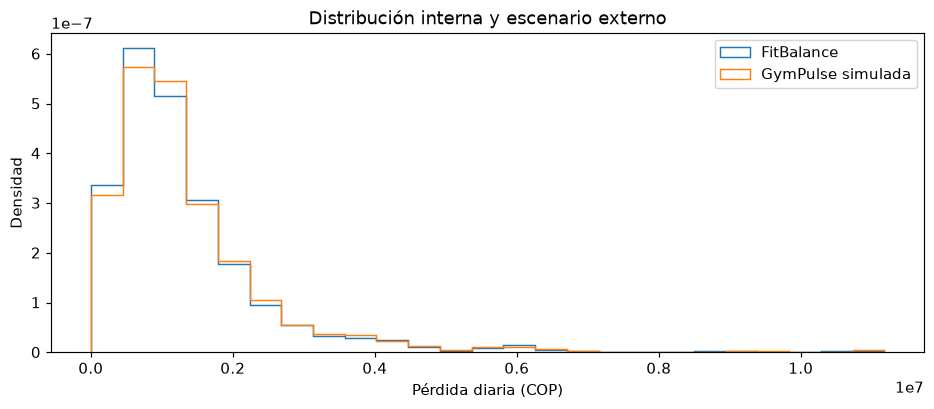

In [2]:
resumen_fuentes = pd.DataFrame({
    "Fuente": ["FitBalance", "GymPulse simulada"],
    "Registros": [len(LDA), len(LDAe)],
    "Media_COP": [LDA.mean(), LDAe.mean()],
    "Desviacion_COP": [LDA.std(), LDAe.std()],
    "Dias_sin_cancelaciones": [np.sum(Freq == 0), np.sum(Freqe == 0)]
})
print(resumen_fuentes.round(2).to_string(index=False))
resumen_fuentes.to_csv("resultados/01_fuentes.csv", index=False)

limites = np.histogram_bin_edges(np.r_[LDA, LDAe], bins=25)
plt.figure(figsize=(9, 4))
plt.hist(LDA, bins=limites, density=True, histtype="step", label="FitBalance")
plt.hist(LDAe, bins=limites, density=True, histtype="step", label="GymPulse simulada")
plt.xlabel("Pérdida diaria (COP)")
plt.ylabel("Densidad")
plt.title("Distribución interna y escenario externo")
plt.legend()
plt.tight_layout()
plt.savefig("resultados/01_distribuciones.png", dpi=150)
plt.show()


## 3. Modelo 1: integración por pérdida agregada

Se reproduce la integración del ejercicio COSCO: cinco concentradores internos, distancia relativa y pertenencia gaussiana. Se acepta si la pertenencia máxima supera 0,90 y se actualiza el concentrador. La semilla y el orden forman parte del método. Estos concentradores se actualizan por promedio secuencial y **no son medoides**.

El 95 % es un objetivo de calibración de esta base, no una correlación estadística ni una precisión del sistema.

In [3]:
random.seed(42)
XC_int = np.sort(np.array(random.choices(list(LDA), k=5), dtype=float))
Boxes_int = [[] for j in range(5)]
for valor in LDA:
    distancia = np.abs(XC_int - valor) / np.maximum(np.abs(XC_int), 1e-12)
    nc = int(np.argmin(distancia))
    XC_int[nc] = (XC_int[nc] + valor) / 2
    Boxes_int[nc].append(valor)

XC_integrado = XC_int.copy()
Boxes_integradas = [list(caja) for caja in Boxes_int]
aceptados_1 = []
vp_1 = []
for valor in LDAe:
    VP = np.exp(-0.5 * ((XC_integrado - valor) / np.maximum(np.abs(XC_integrado), 1e-12))**2)
    nc = int(np.argmax(VP))
    aceptado = bool(VP[nc] > 0.90)
    aceptados_1.append(aceptado)
    vp_1.append(VP[nc])
    if aceptado:
        Boxes_integradas[nc].append(valor)
        XC_integrado[nc] = (XC_integrado[nc] + valor) / 2

aceptados_1 = np.array(aceptados_1)
m1 = int(aceptados_1.sum())
print("Datos externos aceptados:", m1, "de", len(LDAe))
print("Tasa de integración:", round(100 * aceptados_1.mean(), 2), "%")
LDA_integrada_1 = np.r_[LDA, LDAe[aceptados_1]]


Datos externos aceptados: 1140 de 1200
Tasa de integración: 95.0 %


## 4. Modelo 2: integración multidimensional

Se adapta el ejercicio `4_integracionmultidimencional.ipynb`: entradas frecuencia y severidad, distancia euclidiana, cinco centros y actualización secuencial. Se escalan ambas variables con mínimos y máximos internos para que COP no domine la frecuencia. Los parámetros de escala se ajustan únicamente con la base interna.

Para seleccionar registros externos se añade un criterio explícito: `VP = exp(-0,5 × (distancia/h)²)`, con `h = 0,10` y `VP > 0,90`. Este filtro es una extensión declarada de la clasificación multidimensional de clase. Se informa su sensibilidad a h. El 95 % del modelo 1 no se fuerza aquí.

In [4]:
XD = np.column_stack([Freq, Sev])
XDe = np.column_stack([Freqe, Seve])
minimos = XD.min(axis=0)
rangos = XD.max(axis=0) - minimos
XD_escalado = (XD - minimos) / rangos
XDe_escalado = (XDe - minimos) / rangos

XC = XD_escalado[:5].copy()
for fila in XD_escalado:
    distancias = np.sqrt(np.sum((XC - fila)**2, axis=1))
    nc = int(np.argmin(distancias))
    XC[nc] = (XC[nc] + fila) / 2

aceptados_2 = []
vp_2 = []
XC_multi = XC.copy()
h = 0.10
for fila in XDe_escalado:
    distancias = np.sqrt(np.sum((XC_multi - fila)**2, axis=1))
    VP = np.exp(-0.5 * (distancias / h)**2)
    nc = int(np.argmax(VP))
    aceptado = bool(VP[nc] > 0.90)
    aceptados_2.append(aceptado)
    vp_2.append(VP[nc])
    if aceptado:
        XC_multi[nc] = (XC_multi[nc] + fila) / 2

aceptados_2 = np.array(aceptados_2)
LDA_integrada_2 = np.r_[LDA, LDAe[aceptados_2]]
print("Aceptados por dos variables:", aceptados_2.sum(), "de", len(LDAe))
print("Tasa de integración:", round(100 * aceptados_2.mean(), 2), "%")

sensibilidad_multi = []
for ancho in [0.05, 0.10, 0.20]:
    centros = XC.copy()
    cantidad = 0
    for fila in XDe_escalado:
        distancia = np.sqrt(np.sum((centros - fila)**2, axis=1))
        nc = int(np.argmin(distancia))
        if np.exp(-0.5 * (distancia[nc] / ancho)**2) > 0.90:
            cantidad += 1
            centros[nc] = (centros[nc] + fila) / 2
    sensibilidad_multi.append({"h": ancho, "Aceptados": cantidad, "Porcentaje": cantidad / len(LDAe) * 100})
sensibilidad_multi = pd.DataFrame(sensibilidad_multi)
print(sensibilidad_multi.round(2).to_string(index=False))
sensibilidad_multi.to_csv("resultados/02_sensibilidad_multidimensional.csv", index=False)


Aceptados por dos variables: 212 de 1200
Tasa de integración: 17.67 %
   h  Aceptados  Porcentaje
0.05         39        3.25
0.10        212       17.67
0.20        837       69.75


## 5. Comparación de los dos modelos

Se usan momentos sobre las observaciones sin agrupar para evitar que los límites del histograma cambien la comparación. Asimetría y curtosis son momentos poblacionales estandarizados, con curtosis de Pearson. La comparación describe el escenario calibrado; no es una validación con observaciones nuevas independientes.

                       Interna      Modelo_1      Modelo_2
Media             1.324056e+06  1.331456e+06  1.265165e+06
Varianza          1.416150e+12  1.310322e+12  1.274012e+12
Desviacion        1.190021e+06  1.144693e+06  1.128721e+06
Asimetria         3.054500e+00  2.757400e+00  3.175600e+00
Curtosis_Pearson  1.795920e+01  1.508220e+01  1.954260e+01
Diferencias porcentuales frente a la interna:
                  Modelo_1  Modelo_2
Media                 0.56      4.45
Varianza              7.47     10.04
Desviacion            3.81      5.15
Asimetria             9.73      3.97
Curtosis_Pearson     16.02      8.82


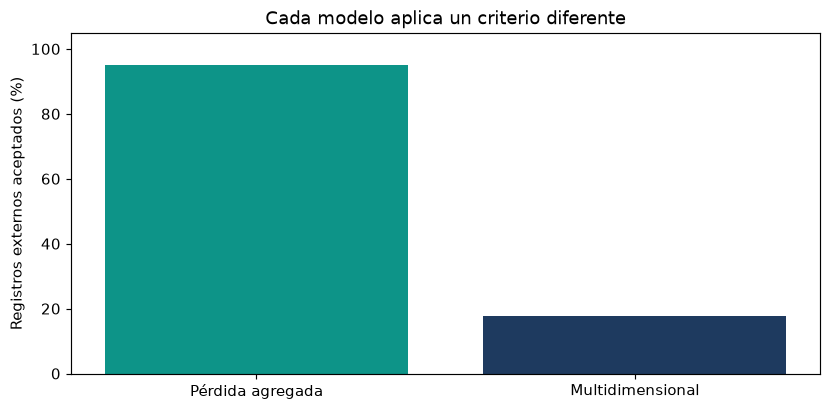

In [5]:
def medidas(Xi):
    media = np.mean(Xi)
    varianza = np.var(Xi)
    desviacion = np.sqrt(varianza)
    return [media, varianza, desviacion,
            np.mean((Xi - media)**3) / desviacion**3,
            np.mean((Xi - media)**4) / desviacion**4]

comparacion = pd.DataFrame({
    "Interna": medidas(LDA),
    "Modelo_1": medidas(LDA_integrada_1),
    "Modelo_2": medidas(LDA_integrada_2)
}, index=["Media", "Varianza", "Desviacion", "Asimetria", "Curtosis_Pearson"])
errores = comparacion[["Modelo_1", "Modelo_2"]].sub(comparacion["Interna"], axis=0).abs().div(comparacion["Interna"].abs(), axis=0) * 100
print(comparacion.round(4).to_string())
print("Diferencias porcentuales frente a la interna:")
print(errores.round(2).to_string())
comparacion.to_csv("resultados/03_momentos.csv")
errores.to_csv("resultados/04_discrepancias.csv")

aceptacion = pd.DataFrame({
    "Modelo": ["Pérdida agregada", "Multidimensional"],
    "Aceptados": [m1, int(aceptados_2.sum())],
    "Porcentaje": [100 * aceptados_1.mean(), 100 * aceptados_2.mean()]
})
aceptacion.to_csv("resultados/05_aceptacion.csv", index=False)
plt.figure(figsize=(8, 4))
plt.bar(aceptacion["Modelo"], aceptacion["Porcentaje"], color=["#0d9488", "#1e3a5f"])
plt.ylabel("Registros externos aceptados (%)")
plt.ylim(0, 105)
plt.title("Cada modelo aplica un criterio diferente")
plt.tight_layout()
plt.savefig("resultados/02_aceptacion.png", dpi=150)
plt.show()

trazabilidad = pd.DataFrame({"ID": ["GP_" + str(i + 1) for i in range(len(GymPulse))],
    "Pertenencia_modelo_1": vp_1, "Aceptado_modelo_1": aceptados_1,
    "Pertenencia_modelo_2": vp_2, "Aceptado_modelo_2": aceptados_2})
trazabilidad.to_csv("resultados/06_decisiones_integracion.csv", index=False)


## 6. Credibilidad como contraste adicional

Se conserva la fórmula simplificada de clase para EPV, VHM y Cr. El complemento pondera la media hipotética, no certifica confiabilidad externa. La dependencia de la simulación con la interna impide tratar el ejercicio como una aplicación actuarial independiente.

In [6]:
ND = len(LDA)
NDe = len(LDAe)
uo = np.mean(LDA)
ue = np.mean(LDAe)
EPV = (ND * np.var(LDA) + NDe * np.var(LDAe)) / (ND + NDe)
uh = (ND * uo + NDe * ue) / (ND + NDe)
VHM = (ND * (uo - uh)**2 + NDe * (ue - uh)**2) / (ND + NDe)
Cr = ND / (ND + EPV / VHM) if VHM > 0 else 0.0
u_cred = Cr * uo + (1 - Cr) * uh
print("EPV (COP²):", EPV)
print("VHM (COP²):", VHM)
print("Peso de la media propia:", round(Cr * 100, 2), "%")
print("Complemento sobre la media hipotética:", round((1 - Cr) * 100, 2), "%")
print("Media ajustada:", round(u_cred, 2), "COP")


EPV (COP²): 1459272182222.6443
VHM (COP²): 394452953.6499234
Peso de la media propia: 24.49 %
Complemento sobre la media hipotética: 75.51 %
Media ajustada: 1339052.43 COP


## 7. Caracterización difusa sobre la base interna

Se usa la interna para evitar que la calibración externa determine el modelo de gestión. Los días sin cancelaciones se conservan con pérdida cero y se separan para obtener los grupos de frecuencia y severidad. PAM selecciona medoides reales. Se aplican los anchos gaussianos y la matriz de impacto de clase.

In [7]:
def clusterizacion(Xi):
    # Cinco semillas tomadas de los valores observados.
    valores = np.unique(Xi)
    posiciones = np.linspace(0, len(valores) - 1, 5).astype(int)
    XC = valores[posiciones].copy()
    distancias = np.abs(Xi[:, None] - valores)

    # Intercambiar medoides mientras se reduzca el costo.
    while True:
        costo = np.abs(Xi[:, None] - XC).min(axis=1).sum()
        mejor_costo = costo
        mejores_centros = XC.copy()

        for j in range(5):
            otros = np.delete(XC, j)
            distancia_otros = np.abs(Xi[:, None] - otros).min(axis=1)
            costos = np.minimum(distancias, distancia_otros[:, None]).sum(axis=0)
            candidato = int(np.argmin(costos))

            if costos[candidato] < mejor_costo - 0.000001:
                mejor_costo = costos[candidato]
                mejores_centros = XC.copy()
                mejores_centros[j] = valores[candidato]

        if mejor_costo >= costo - 0.000001:
            break
        XC = mejores_centros

    XC = np.sort(XC)
    nc = np.abs(Xi[:, None] - XC).argmin(axis=1)
    return XC, nc


Medoides de frecuencia: [2. 3. 4. 5. 8.]
Medoides de severidad: [153298.72963621 222078.60599191 328341.58333145 485958.14167783
 752078.81879716]
Días con eventos en ME: 1180


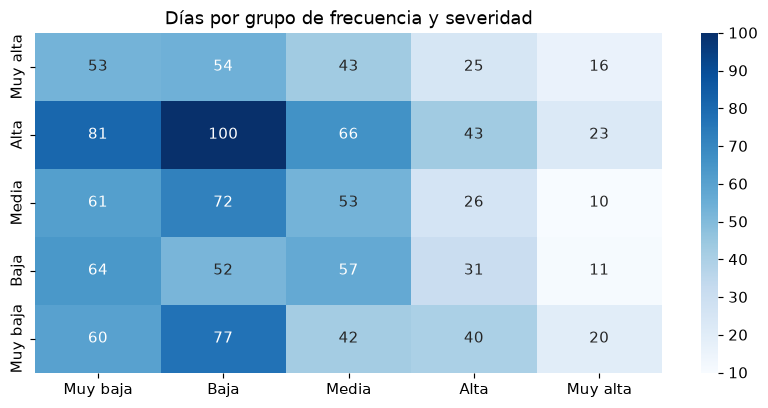

In [8]:
con_evento = Freq > 0
Xf = Freq[con_evento]
Xs = Sev[con_evento]
XCf, ncf = clusterizacion(Xf)
XCs, ncs = clusterizacion(Xs)
lbf = ["Muy baja", "Baja", "Media", "Alta", "Muy alta"]
lbs = ["Muy baja", "Baja", "Media", "Alta", "Muy alta"]
sigmaf = np.array([np.sqrt(np.sum((XCf - v)**2) / 4) for v in XCf])
sigmas = np.array([np.sqrt(np.sum((XCs - v)**2) / 4) for v in XCs])
MP = np.outer(XCf, XCs)
ME = np.zeros((5, 5), dtype=int)
for k in range(len(Xf)):
    ME[int(ncf[k]), int(ncs[k])] += 1
MI = np.array([[1,1,1,2,2], [1,2,2,3,3], [1,2,3,3,4], [2,3,3,4,4], [2,3,4,4,5]])
print("Medoides de frecuencia:", XCf)
print("Medoides de severidad:", XCs)
print("Días con eventos en ME:", ME.sum())
plt.figure(figsize=(8, 4))
sns.heatmap(ME[::-1], annot=True, fmt="d", cmap="Blues", xticklabels=lbs, yticklabels=lbf[::-1])
plt.title("Días por grupo de frecuencia y severidad")
plt.tight_layout()
plt.savefig("resultados/03_matriz_eventos.png", dpi=150)
plt.show()


## 8. Prospectiva y potencial de financiación de captura

Se aplica la matriz de gestión de clase: `MG[(MG > 1) & (MG < 5)] *= NG`. La pérdida gestionada divide el numerador con MI por el denominador con MG. La mejora al aumentar NG es una consecuencia matemática de esa regla, no una eficacia aprendida con intervenciones reales.

Se comparan pérdidas modeladas con la misma referencia NG=1. Nunca se interpreta la diferencia entre la pérdida observada y la difusa como ahorro. Para el horizonte futuro se supone el promedio diario histórico constante, sin estacionalidad ni inflación. El costo incremental es frecuencia media × días × costo por contacto × (NG−1).

Solo el 10 % del neto positivo se destina a GEI, bajo un costo hipotético de COP 300.000/tCO₂e. Este cálculo representa toneladas cuya captura podría financiarse. Faltan mediciones de emisiones, tecnología, adicionalidad y certificación para afirmar captura física. No se presenta un precio de mercado ni se requiere una tasa de cambio.

 NG  Media_modelada_COP  Bruto_horizonte_COP  Costo_gestion_COP  Neto_horizonte_COP  Presupuesto_GEI_COP  Captura_financiable_tCO2e  Exposicion_indice
1.0          1591349.94                 0.00                0.0                0.00                 0.00                       0.00               1.00
1.1          1466711.70          45492957.74          4713975.0         40778982.74           4077898.27                      13.59               0.93
1.2          1360242.42          84354244.20          9427950.0         74926294.20           7492629.42                      24.98               0.87
1.5          1117191.02         173068006.83         23569875.0        149498131.83          14949813.18                      49.83               0.75
2.0           861097.44         266542162.69         47139750.0        219402412.69          21940241.27                      73.13               0.62
Mejor NG entre los probados, bajo estos supuestos: 2.0


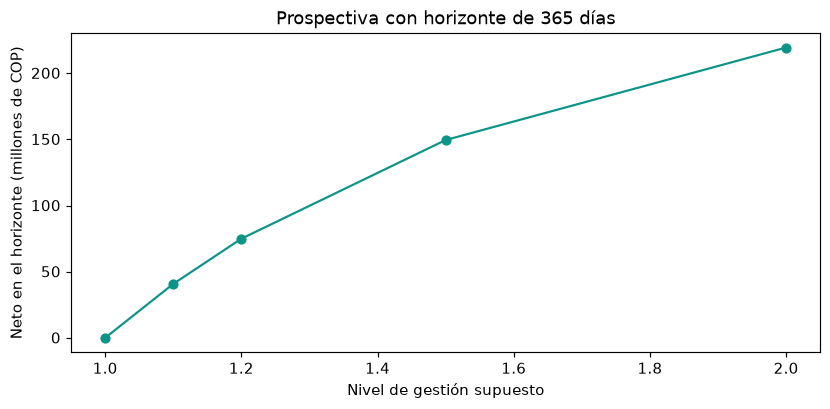

In [9]:
pesos = []
for k in range(len(Xf)):
    VPf = np.exp(-0.5 * ((XCf - Xf[k]) / sigmaf)**2)
    VPs = np.exp(-0.5 * ((XCs - Xs[k]) / sigmas)**2)
    pesos.append(np.outer(VPf, VPs) * ME)
pesos = np.array(pesos)
numerador = np.sum(pesos * MI * MP, axis=(1, 2))
LDAm0ref = np.zeros(len(Freq))
LDAm0ref[con_evento] = numerador / np.sum(pesos * MI, axis=(1, 2))
prospectiva = []
for escenario in escenarios.itertuples():
    NG = escenario.NG
    MG = MI.copy().astype(float)
    MG[(MG > 1) & (MG < 5)] *= NG
    LDAm5 = np.zeros(len(Freq))
    LDAm5[con_evento] = numerador / np.sum(pesos * MG, axis=(1, 2))
    bruto = max(0, (LDAm0ref.mean() - LDAm5.mean()) * escenario.Horizonte_dias)
    costo = Freq.mean() * escenario.Horizonte_dias * escenario.Costo_contacto_COP * (NG - 1)
    neto = bruto - costo
    presupuesto_gei = max(0, neto) * escenario.Fraccion_para_GEI
    TC = presupuesto_gei / escenario.Costo_tCO2e_COP
    prospectiva.append({"NG": NG, "Media_modelada_COP": LDAm5.mean(), "Bruto_horizonte_COP": bruto,
        "Costo_gestion_COP": costo, "Neto_horizonte_COP": neto,
        "Presupuesto_GEI_COP": presupuesto_gei, "Captura_financiable_tCO2e": TC,
        "Exposicion_indice": np.mean(MI / MG)})
prospectiva = pd.DataFrame(prospectiva)
print(prospectiva.round(2).to_string(index=False))
prospectiva.to_csv("resultados/07_prospectiva.csv", index=False)
mejor = prospectiva.loc[prospectiva["Neto_horizonte_COP"].idxmax()]
print("Mejor NG entre los probados, bajo estos supuestos:", mejor["NG"])

plt.figure(figsize=(8, 4))
plt.plot(prospectiva["NG"], prospectiva["Neto_horizonte_COP"] / 1e6, marker="o", color="#0d9488")
plt.xlabel("Nivel de gestión supuesto")
plt.ylabel("Neto en el horizonte (millones de COP)")
plt.title("Prospectiva con horizonte de 365 días")
plt.tight_layout()
plt.savefig("resultados/04_neto.png", dpi=150)
plt.show()


## 9. Sensibilidad y decisiones

El costo por tonelada se cambia a COP 150.000, 300.000 y 600.000. Son supuestos comparables. Se informa también el costo máximo por contacto que haría cero el neto del mejor escenario; esto permite discutir cuándo deja de ser atractivo. El mejor NG se elige solo entre cinco casos y con el mismo conjunto usado para caracterizar el riesgo, no mediante optimización predictiva validada.

 Costo_COP_tCO2e  Captura_financiable_tCO2e
          150000                     146.27
          300000                      73.13
          600000                      36.57
Costo de contacto de equilibrio para ese NG: 169628.92 COP


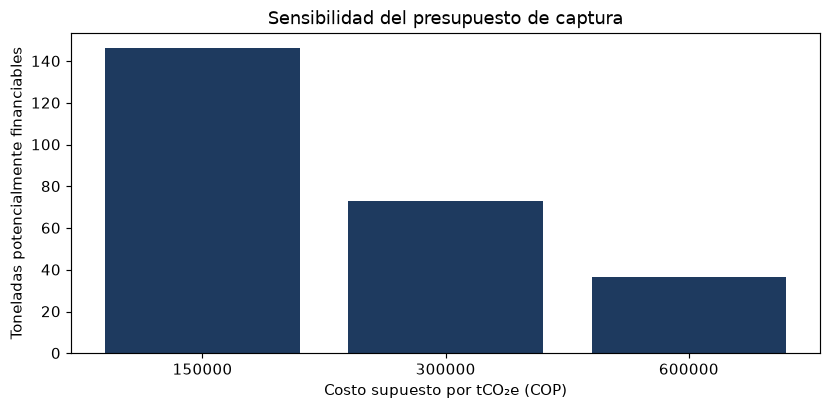

In [10]:
sensibilidad_gei = pd.DataFrame({"Costo_COP_tCO2e": [150000, 300000, 600000]})
sensibilidad_gei["Captura_financiable_tCO2e"] = mejor["Presupuesto_GEI_COP"] / sensibilidad_gei["Costo_COP_tCO2e"]
print(sensibilidad_gei.round(2).to_string(index=False))
sensibilidad_gei.to_csv("resultados/08_sensibilidad_GEI.csv", index=False)
contactos = Freq.mean() * 365 * (mejor["NG"] - 1)
punto_equilibrio = mejor["Bruto_horizonte_COP"] / contactos if contactos > 0 else np.nan
print("Costo de contacto de equilibrio para ese NG:", round(punto_equilibrio, 2), "COP")
plt.figure(figsize=(8, 4))
plt.bar(sensibilidad_gei["Costo_COP_tCO2e"].astype(str), sensibilidad_gei["Captura_financiable_tCO2e"], color="#1e3a5f")
plt.xlabel("Costo supuesto por tCO₂e (COP)")
plt.ylabel("Toneladas potencialmente financiables")
plt.title("Sensibilidad del presupuesto de captura")
plt.tight_layout()
plt.savefig("resultados/05_sensibilidad_GEI.png", dpi=150)
plt.show()


## 10. Análisis y conclusión para la organización

In [11]:
print("ANÁLISIS FINAL")
print(f"Las dos fuentes contienen {len(LDA)} y {len(LDAe)} registros. La diferencia de sus medias es {(ue / uo - 1) * 100:.2f}% por construcción de la simulación.")
print(f"El modelo de pérdida agregada admite {m1} registros ({aceptados_1.mean():.2%}); el multidimensional admite {aceptados_2.sum()} ({aceptados_2.mean():.2%}).")
print("La diferencia de aceptación confirma que frecuencia y severidad por separado aportan un criterio distinto del producto agregado.")
print(f"La media del conjunto integrado cambia {errores.loc['Media', 'Modelo_1']:.2f}% con el modelo 1 y {errores.loc['Media', 'Modelo_2']:.2f}% con el modelo 2.")
print(f"En credibilidad, Cr es {Cr:.2%} y el complemento sobre la media hipotética es {1-Cr:.2%}. Estos pesos no evalúan veracidad de las bases.")
print(f"En la prospectiva, NG={mejor['NG']:.1f} obtiene el mayor neto entre los escenarios: COP {mejor['Neto_horizonte_COP']:,.2f} en 365 días.")
print(f"Destinar el 10% del neto positivo a captura, a COP 300.000 por tonelada, permitiría financiar {mejor['Captura_financiable_tCO2e']:,.2f} tCO2e en el escenario.")
print("Se recomienda validar costos de contacto y respuesta real de retención en un piloto temporal antes de ampliar la gestión.")
print("Se debe medir por separado la captura física y completar el diseño de un proyecto ambiental verificable.")
print("La similitud de las fuentes responde a su calibración. Se necesita una fuente externa independiente para evaluar generalización.")


ANÁLISIS FINAL
Las dos fuentes contienen 1200 y 1200 registros. La diferencia de sus medias es 3.00% por construcción de la simulación.
El modelo de pérdida agregada admite 1140 registros (95.00%); el multidimensional admite 212 (17.67%).
La diferencia de aceptación confirma que frecuencia y severidad por separado aportan un criterio distinto del producto agregado.
La media del conjunto integrado cambia 0.56% con el modelo 1 y 4.45% con el modelo 2.
En credibilidad, Cr es 24.49% y el complemento sobre la media hipotética es 75.51%. Estos pesos no evalúan veracidad de las bases.
En la prospectiva, NG=2.0 obtiene el mayor neto entre los escenarios: COP 219,402,412.69 en 365 días.
Destinar el 10% del neto positivo a captura, a COP 300.000 por tonelada, permitiría financiar 73.13 tCO2e en el escenario.
Se recomienda validar costos de contacto y respuesta real de retención en un piloto temporal antes de ampliar la gestión.
Se debe medir por separado la captura física y completar el diseño d

## 11. Reproducibilidad y alcance

Los resultados y las figuras se guardan en `resultados/`. El portafolio incluye las bases, este notebook, el script reproducible, el diccionario, los supuestos, las pruebas, la presentación y el guion del video.

**Referencias del curso:** notebook de integración COSCO, notebook `4_integracionmultidimencional.ipynb`, teoría de credibilidad y Fuzzy Logic proporcionados durante el curso. Se documenta la extensión del filtro multidimensional y la corrección de centros a PAM para la etapa difusa. El notebook distingue la base original, la simulación calibrada y los supuestos de gestión.

**Entrega y presentación:** el video dura como máximo diez minutos. El documento del reto exige asistencia presencial y permanencia hasta el final; ese requisito no lo reemplazan los archivos. Si se incluye narración sintética, será material de apoyo y no corresponderá a las voces de los integrantes.